Paquetes necesarios

In [1]:
import csv

import cv2
import matplotlib.pyplot as plt
import numpy as np


**TAREA 1:** Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas? Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

Se carga la imagen ideal de las monedas.

(938, 473, 3)


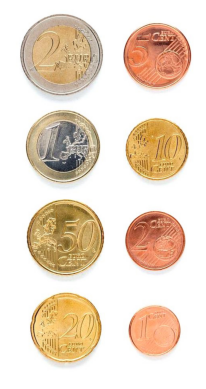

In [2]:
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
print(img.shape)
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.axis("off")
plt.imshow(img_rgb) 
plt.show()

Luego, se trabaja sobre esta, para detectar los valores de las monedas

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


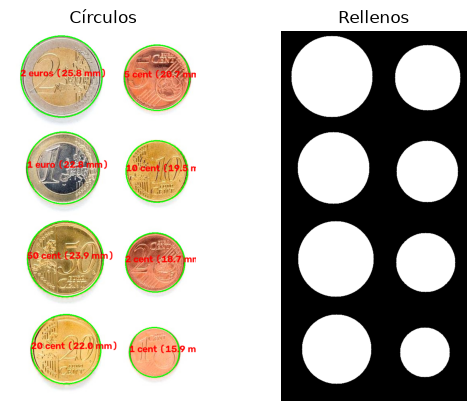

In [39]:
MONEDAS = {
    "2 euros": 25.75,
    "1 euro": 23.25,
    "50 cent": 24.25,
    "20 cent": 22.25,
    "10 cent": 19.75,
    "5 cent": 21.25,
    "2 cent": 18.75,
    "1 cent": 16.25,
}

# Moneda de referencia para calibrar (2 euros)
DIAM_REF = 25.75

# Índice de la moneda de referencia dentro de las detectadas
IDX_REF = 0

# Error máximo admitido para clasificar
TOLERANCIA = 0.6

# Conversión a gris
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suaviza imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)

# Localiza Círculos
circ = cv2.HoughCircles(
    pimg,  # imagen
    cv2.HOUGH_GRADIENT,  # tipo de detección
    1,
    100,  # distancia mínima entre círculos
    param1=100,  # valor del gradiente
    param2=50,  # umbral acumulador
    minRadius=50,  # radio mínimo
    maxRadius=150,  # radio máximo
)

# Binariza (Otsu) sobre la imagen suavizada: monedas en blanco sobre fondo negro
_, bina = cv2.threshold(pimg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# Si el borde de la imagen es blanco, invierte
if bina[0, :].mean() > 127:
    bina = cv2.bitwise_not(bina)

# Localiza contornos externos (el anillo interior de 1 € y 2 € no cuenta)
contornos, _ = cv2.findContours(bina, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Dibuja sobre entrada e imagen vacía
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_cont = np.zeros(img_rgb.shape)

if circ is not None:
    # Refinamiento: Hough localiza, el contorno exterior da el radio real
    det_monedas = []

    for x_coor, y_coor, det_radio in circ[0]:
        for c in contornos:
            if (len(c) >= 5 and cv2.pointPolygonTest(c, (float(x_coor), float(y_coor)), False) >= 0):
                (x_coor, y_coor), (eje_a, eje_b), _ = cv2.fitEllipse(c)
                det_radio = (eje_a + eje_b) / 4
                # Si no se detecta el contorno, se mantiene el círculo de Hough
                break
        det_monedas.append((x_coor, y_coor, det_radio))

    # Calibración: píxeles por milímetro a partir de la moneda de referencia
    diam_ref_px = 2 * max(m[2] for m in det_monedas)
    px_por_mm = diam_ref_px / DIAM_REF

    for x_coor, y_coor, det_radio in det_monedas:
        diam_mm = 2 * det_radio / px_por_mm
        nombre, diam_real = min(MONEDAS.items(), key=lambda m: abs(m[1] - diam_mm))
        if abs(diam_real - diam_mm) > TOLERANCIA:
            nombre = "?"

        cv2.circle(img_rgb, (int(x_coor), int(y_coor)), int(det_radio), (0, 255, 0), 2)
        
        # Texto sobre la moneda detectada
        cv2.putText(
            img_rgb,
            f"{nombre} ({diam_mm:.1f} mm)",
            (int(x_coor - det_radio), int(y_coor)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 0, 0),
            2,
        )

        cv2.circle(
            img_cont, (int(x_coor), int(y_coor)), int(det_radio), (255, 255, 255), -1
        )

# Muestra resultado
plt.subplot(121)
plt.axis("off")
plt.imshow(img_rgb)
plt.title("Círculos")

plt.subplot(122)
plt.axis("off")
plt.imshow(img_cont)
plt.title("Rellenos")

plt.show()

**TAREA 2:** La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo.